# SAINT for Cardiovascular Disease Prediction
## Self-Attention and Intersample Attention Transformer

**Model**: SAINT (Somepalli et al., 2021)  
**Reference**: Somepalli, G., Goldblum, M., Schwarzschild, A., Bruss, C. B., & Goldstein, T. (2021). SAINT: Improved Neural Networks for Tabular Data via Row Attention and Contrastive Pre-Training. arXiv:2106.01342.

**Dataset**: Heart_disease_clean.csv (68,653 records, 11 features)

**Why SAINT?**
- **Self-Attention**: Learns feature interactions (like FT-Transformer)
- **Intersample Attention**: Learns from relationships between data points (unique to SAINT)
- **State-of-the-art**: Consistently outperforms TabNet and FT-Transformer on medical datasets
- **Interpretable**: Attention weights show both feature and sample importance

---

## Sections
1. Install & Import Libraries
2. Load & Preprocess Data
3. Feature Engineering
4. Train/Validation/Test Split
5. SAINT Architecture
6. Train SAINT Model
7. Training Curves
8. Evaluate on Test Set
9. SHAP Explainability
10. Confusion Matrix
11. ROC & Precision-Recall Curves
12. Compare with All Models
13. Save Model & Results

## 1. Install & Import Libraries

In [1]:
!pip install torch scikit-learn pandas numpy matplotlib seaborn shap einops -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
import math
from einops import rearrange, repeat
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    average_precision_score
)

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Device configuration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

Using device: cuda
GPU: NVIDIA GeForce GTX 1650
Memory: 4.29 GB


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# ============================================
# RELOAD CSV FRESH
# ============================================
df = pd.read_csv('Heart_disease_clean.csv')
print(f"✅ Dataset loaded: {df.shape}")
print(f"\nTarget values:")
print(df['cardiovascular disease'].value_counts())

# ============================================
# CONVERT TARGET
# ============================================
if df['cardiovascular disease'].dtype == 'object':
    df['cardiovascular disease'] = df['cardiovascular disease'].map({
        'has cardiovascular disease': 1, 
        'does not have cardiovascular disease': 0
    })
    print("\n✅ Converted target to 0/1")

# ============================================
# FEATURE ENGINEERING
# ============================================
df['PP'] = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']
df['MAP'] = (df['ap_hi(Systolic blood pressure)'] + 2 * df['ap_lo(Diastolic blood pressure)']) / 3
df['SBP'] = df['ap_hi(Systolic blood pressure)']
df['DBP'] = df['ap_lo(Diastolic blood pressure)']

df['RiskCount'] = (
    (df['smoking'] == 1).astype(int) + 
    (df['alcohol'] == 1).astype(int) + 
    (df['cholesterol(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    (df['Glucose(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    (df['BMI'] > 30).astype(int)
)

# ============================================
# SELECT FEATURES
# ============================================
feature_cols = [
    'Gender (0: female, 1: male)', 
    'age(years)', 
    'BMI', 
    'SBP', 
    'DBP', 
    'PP', 
    'MAP',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)', 
    'Glucose(1: normal, 2: above normal, 3: well above normal)', 
    'smoking', 
    'alcohol', 
    'active', 
    'RiskCount'
]

X = df[feature_cols].values
y = df['cardiovascular disease'].values

print(f'\n✅ Feature matrix: {X.shape}')
print(f'✅ Target: {y.shape}')
print(f'✅ Class 0: {np.sum(y==0)}, Class 1: {np.sum(y==1)}')

# ============================================
# SPLIT DATA
# ============================================
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_temp
)

print(f'\nTrain set: {X_train.shape[0]} samples')
print(f'Validation set: {X_val.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')

# ============================================
# STANDARDIZE
# ============================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'\n✅ Feature scaling complete.')
print(f'Train mean: {X_train_scaled.mean():.4f}, std: {X_train_scaled.std():.4f}')
print('\n' + '='*50)
print('✅ DATA PREPARATION COMPLETE!')
print('='*50)

✅ Dataset loaded: (68653, 11)

Target values:
cardiovascular disease
does not have cardiovascular disease    34706
has cardiovascular disease              33947
Name: count, dtype: int64

✅ Converted target to 0/1

✅ Feature matrix: (68653, 13)
✅ Target: (68653,)
✅ Class 0: 34706, Class 1: 33947

Train set: 48055 samples
Validation set: 10300 samples
Test set: 10298 samples

✅ Feature scaling complete.
Train mean: -0.0000, std: 1.0000

✅ DATA PREPARATION COMPLETE!


## 2. Load & Preprocess Data

In [4]:
# Load dataset
df = pd.read_csv('Heart_disease_clean.csv')

print(f'Dataset shape: {df.shape}')
print(f'\nColumn names:')
print(df.columns.tolist())
print(f'\nFirst few rows:')
df.head()

Dataset shape: (68653, 11)

Column names:
['Gender (0: female, 1: male)', 'age(years)', 'BMI', 'ap_hi(Systolic blood pressure)', 'ap_lo(Diastolic blood pressure)', 'cholesterol(1: normal, 2: above normal, 3: well above normal)', 'Glucose(1: normal, 2: above normal, 3: well above normal)', 'smoking', 'alcohol', 'active', 'cardiovascular disease']

First few rows:


,"Gender (0: female, 1: male)",age(years),BMI,ap_hi(Systolic blood pressure),ap_lo(Diastolic blood pressure),"cholesterol(1: normal, 2: above normal, 3: well above normal)","Glucose(1: normal, 2: above normal, 3: well above normal)",smoking,alcohol,active,cardiovascular disease
0,1,50,21.967120,110,80,1,1,0,0,1,does not have cardiovascular disease
1,0,55,34.927679,140,90,3,1,0,0,1,has cardiovascular disease
2,0,52,23.507805,130,70,3,1,0,0,0,has cardiovascular disease
3,1,48,28.710479,150,100,1,1,0,0,1,has cardiovascular disease
4,0,48,23.011177,100,60,1,1,0,0,0,does not have cardiovascular disease


In [5]:
# ── Second cleaning pass (brings 68653 → 68534, matches all other notebooks) ──
SBP_COL = 'ap_hi(Systolic blood pressure)'
DBP_COL = 'ap_lo(Diastolic blood pressure)'

before = len(df)
df['_PP'] = df[SBP_COL] - df[DBP_COL]
df = df[
    df['BMI'].between(10, 60) &
    (df['_PP'] > 0)
].reset_index(drop=True)
df = df.drop(columns=['_PP'])

print(f"Rows: {before} → {len(df)}  (removed {before - len(df)})")
# Must print: Rows: 68653 → 68534  (removed 119)

Rows: 68653 → 68534  (removed 119)


In [6]:
# Check for missing values
print('Missing values:')
print(df.isnull().sum())

# Check class distribution
print(f'\nClass distribution:')
print(df['cardiovascular disease'].value_counts())
print(f'\nClass balance: {df["cardiovascular disease"].value_counts(normalize=True)}')

Missing values:
Gender (0: female, 1: male)                                      0
age(years)                                                       0
BMI                                                              0
ap_hi(Systolic blood pressure)                                   0
ap_lo(Diastolic blood pressure)                                  0
cholesterol(1: normal, 2: above normal, 3: well above normal)    0
Glucose(1: normal, 2: above normal, 3: well above normal)        0
smoking                                                          0
alcohol                                                          0
active                                                           0
cardiovascular disease                                           0
dtype: int64

Class distribution:
cardiovascular disease
does not have cardiovascular disease    34648
has cardiovascular disease              33886
Name: count, dtype: int64

Class balance: cardiovascular disease
does not have cardiovascular dise

## 3. Feature Engineering

In [7]:
# Cell — Feature Engineering (CANONICAL — matches Phases 1-4 exactly)

# ── Column name definitions ────────────────────────────────────────────
SBP_COL  = 'ap_hi(Systolic blood pressure)'
DBP_COL  = 'ap_lo(Diastolic blood pressure)'
CHOL_COL = 'cholesterol(1: normal, 2: above normal, 3: well above normal)'
GLUC_COL = 'Glucose(1: normal, 2: above normal, 3: well above normal)'

# ── Encode target (add this — VIME/SAINT keep original column name) ────
df['target'] = df['cardiovascular disease'].map({
    'has cardiovascular disease'        : 1,
    'does not have cardiovascular disease': 0
})
print(f"Target distribution:\n{df['target'].value_counts()}")
print(f"Missing target values: {df['target'].isna().sum()}")

# ── Short aliases ──────────────────────────────────────────────────────
df['SBP'] = df[SBP_COL]
df['DBP'] = df[DBP_COL]

# ── Engineered Feature 1: Pulse Pressure ──────────────────────────────
df['PP']  = df[SBP_COL] - df[DBP_COL]

# ── Engineered Feature 2: Mean Arterial Pressure ──────────────────────
df['MAP'] = (df[SBP_COL] + 2 * df[DBP_COL]) / 3

# ── Engineered Feature 3: RiskCount (CANONICAL DEFINITION) ───────────
df['RiskCount'] = (
    (df[CHOL_COL] > 1).astype(int) +
    (df[GLUC_COL]  > 1).astype(int) +
    df['smoking'].astype(int)        +
    df['alcohol'].astype(int)        +
    (1 - df['active'].astype(int))
)

# ── Verification ──────────────────────────────────────────────────────
print("\nFeature Engineering Complete")
print(f"  PP       : mean={df['PP'].mean():.2f}  min={df['PP'].min()}  max={df['PP'].max()}")
print(f"  MAP      : mean={df['MAP'].mean():.2f}  min={df['MAP'].min():.2f}  max={df['MAP'].max():.2f}")
print(f"  RiskCount distribution:")
print(df['RiskCount'].value_counts().sort_index().to_string())

# ── 13-Feature List ────────────────────────────────────────────────────
FEATURE_COLS = [
    'Gender (0: female, 1: male)',
    'age(years)',
    'BMI',
    'SBP',
    'DBP',
    CHOL_COL,
    GLUC_COL,
    'smoking',
    'alcohol',
    'active',
    'PP',
    'MAP',
    'RiskCount',
]

FEAT_NAMES = [
    'Gender', 'Age', 'BMI', 'SBP', 'DBP',
    'Cholesterol', 'Glucose', 'Smoking',
    'Alcohol', 'Active', 'PP', 'MAP', 'RiskCount'
]

assert len(FEATURE_COLS) == 13
assert len(FEAT_NAMES)   == 13

X = df[FEATURE_COLS].values.astype(np.float32)
y = df['target'].values.astype(np.int64)

print(f"\nFeature matrix : {X.shape}")
print(f"Target vector  : {y.shape}")
print(f"\nAll 13 features:")
for i, (col, name) in enumerate(zip(FEATURE_COLS, FEAT_NAMES)):
    print(f"  [{i+1:02d}] {name:<12}  ←  {col}")

Target distribution:
target
0    34648
1    33886
Name: count, dtype: int64
Missing target values: 0

Feature Engineering Complete
  PP       : mean=45.33  min=5  max=135
  MAP      : mean=96.37  min=53.33  max=153.33
  RiskCount distribution:
RiskCount
0    34112
1    21615
2     9858
3     2622
4      293
5       34

Feature matrix : (68534, 13)
Target vector  : (68534,)

All 13 features:
  [01] Gender        ←  Gender (0: female, 1: male)
  [02] Age           ←  age(years)
  [03] BMI           ←  BMI
  [04] SBP           ←  SBP
  [05] DBP           ←  DBP
  [06] Cholesterol   ←  cholesterol(1: normal, 2: above normal, 3: well above normal)
  [07] Glucose       ←  Glucose(1: normal, 2: above normal, 3: well above normal)
  [08] Smoking       ←  smoking
  [09] Alcohol       ←  alcohol
  [10] Active        ←  active
  [11] PP            ←  PP
  [12] MAP           ←  MAP
  [13] RiskCount     ←  RiskCount


## 4. Train/Validation/Test Split

In [8]:
# Split: 70% train, 15% validation, 15% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_temp  # 0.1765 * 0.85 ≈ 0.15
)

print(f'Train set: {X_train.shape[0]} samples')
print(f'Validation set: {X_val.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'\nFeature scaling complete.')
print(f'Train mean: {X_train_scaled.mean():.4f}, std: {X_train_scaled.std():.4f}')

Train set: 47971 samples
Validation set: 10282 samples
Test set: 10281 samples

Feature scaling complete.
Train mean: -0.0000, std: 1.0000


In [9]:
# Create PyTorch datasets
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets
train_dataset = TabularDataset(X_train_scaled, y_train)
val_dataset = TabularDataset(X_val_scaled, y_val)
test_dataset = TabularDataset(X_test_scaled, y_test)

# Create data loaders
BATCH_SIZE = 256
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Batch size: {BATCH_SIZE}')
print(f'Training batches: {len(train_loader)}')
print(f'Validation batches: {len(val_loader)}')
print(f'Test batches: {len(test_loader)}')

Batch size: 256
Training batches: 188
Validation batches: 41
Test batches: 41


## 5. SAINT Architecture

SAINT combines:
1. **Self-Attention**: Learns feature interactions within each sample
2. **Intersample Attention**: Learns from relationships between different samples
3. **Feature Embeddings**: Projects each feature into a learned representation

In [10]:
class FeatureEmbedding(nn.Module):
    """Embed each feature into a d-dimensional vector."""
    def __init__(self, n_features, d_model):
        super().__init__()
        self.n_features = n_features
        self.d_model = d_model
        
        # Linear projection for each feature
        self.feature_embeddings = nn.ModuleList([
            nn.Linear(1, d_model) for _ in range(n_features)
        ])
        
        # Learnable positional embeddings for features
        self.feature_positions = nn.Parameter(torch.randn(1, n_features, d_model))
    
    def forward(self, x):
        # x: (batch_size, n_features)
        batch_size = x.size(0)
        
        # Embed each feature separately
        embedded = []
        for i in range(self.n_features):
            # (batch_size, 1) -> (batch_size, d_model)
            feat_emb = self.feature_embeddings[i](x[:, i:i+1])
            embedded.append(feat_emb)
        
        # Stack: (batch_size, n_features, d_model)
        embedded = torch.stack(embedded, dim=1)
        
        # Add positional embeddings
        embedded = embedded + self.feature_positions
        
        return embedded


class SelfAttentionBlock(nn.Module):
    """Multi-head self-attention for feature interactions."""
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # Feed-forward network
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout)
        )
    
    def forward(self, x):
        # Self-attention with residual
        attn_out, _ = self.attention(x, x, x)
        x = self.norm1(x + attn_out)
        
        # Feed-forward with residual
        ffn_out = self.ffn(x)
        x = self.norm2(x + ffn_out)
        
        return x


class IntersampleAttentionBlock(nn.Module):
    """Intersample attention: learn from relationships between samples."""
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # Feed-forward network
        self.ffn = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout)
        )
    
    def forward(self, x):
        # x: (batch_size, n_features, d_model)
        
        # Transpose to (n_features, batch_size, d_model) for intersample attention
        x_t = x.transpose(0, 1)
        
        # Intersample attention: samples attend to other samples
        attn_out, _ = self.attention(x_t, x_t, x_t)
        x_t = self.norm1(x_t + attn_out)
        
        # Feed-forward
        ffn_out = self.ffn(x_t)
        x_t = self.norm2(x_t + ffn_out)
        
        # Transpose back
        return x_t.transpose(0, 1)


class SAINT(nn.Module):
    """SAINT: Self-Attention and Intersample Attention Transformer."""
    def __init__(
        self,
        n_features,
        n_classes=2,
        d_model=64,
        n_heads=4,
        n_layers=3,
        dropout=0.1
    ):
        super().__init__()
        self.n_features = n_features
        self.n_classes = n_classes
        self.d_model = d_model
        
        # Feature embedding
        self.feature_embedding = FeatureEmbedding(n_features, d_model)
        
        # Alternating self-attention and intersample attention blocks
        self.blocks = nn.ModuleList()
        for i in range(n_layers):
            # Self-attention (feature interactions)
            self.blocks.append(SelfAttentionBlock(d_model, n_heads, dropout))
            # Intersample attention (sample relationships)
            self.blocks.append(IntersampleAttentionBlock(d_model, n_heads, dropout))
        
        # Classification head
        self.norm = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(
            nn.Linear(d_model * n_features, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, n_classes)
        )
    
    def forward(self, x):
        # Embed features
        x = self.feature_embedding(x)  # (batch_size, n_features, d_model)
        
        # Apply attention blocks
        for block in self.blocks:
            x = block(x)
        
        # Normalize
        x = self.norm(x)
        
        # Flatten and classify
        x = x.reshape(x.size(0), -1)  # (batch_size, n_features * d_model)
        logits = self.classifier(x)
        
        return logits


# Initialize model
n_features = X_train_scaled.shape[1]

model = SAINT(
    n_features=n_features,
    n_classes=2,
    d_model=64,
    n_heads=8,
    n_layers=4,
    dropout=0.15
).to(DEVICE)

# Count parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nSAINT Model initialized')
print(f'Total parameters: {n_params:,}')
print(f'Model architecture:')
print(model)


SAINT Model initialized
Total parameters: 509,634
Model architecture:
SAINT(
  (feature_embedding): FeatureEmbedding(
    (feature_embeddings): ModuleList(
      (0-12): 13 x Linear(in_features=1, out_features=64, bias=True)
    )
  )
  (blocks): ModuleList(
    (0): SelfAttentionBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.15, inplace=False)
        (3): Linear(in_features=256, out_features=64, bias=True)
        (4): Dropout(p=0.15, inplace=False)
      )
    )
    (1): IntersampleAttentionBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_feature

## 6. Train SAINT Model

In [11]:
# Training configuration
EPOCHS = 50
LR = 1e-3
WEIGHT_DECAY = 1e-4

# Loss function (with class weights for balance)
class_counts = np.bincount(y_train)
class_weights = torch.FloatTensor([1.0 / count for count in class_counts]).to(DEVICE)
class_weights = class_weights / class_weights.sum() * len(class_counts)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print(f'Training configuration:')
print(f'  Epochs: {EPOCHS}')
print(f'  Learning rate: {LR}')
print(f'  Weight decay: {WEIGHT_DECAY}')
print(f'  Class weights: {class_weights.cpu().numpy()}')
print(f'  Optimizer: AdamW')
print(f'  Scheduler: CosineAnnealingLR')

Training configuration:
  Epochs: 50
  Learning rate: 0.001
  Weight decay: 0.0001
  Class weights: [0.98888916 1.0111109 ]
  Optimizer: AdamW
  Scheduler: CosineAnnealingLR


In [12]:
# ============================================
# CREATE PYTORCH DATASETS & DATALOADERS
# ============================================
import torch
from torch.utils.data import Dataset, DataLoader

class SAINTDataset(Dataset):
    """Dataset that returns features and labels"""
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets
train_dataset = SAINTDataset(X_train_scaled, y_train)
val_dataset = SAINTDataset(X_val_scaled, y_val)
test_dataset = SAINTDataset(X_test_scaled, y_test)

# Create dataloaders - CRITICAL: num_workers=0 for Windows!
BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # ← CRITICAL for Windows
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # ← CRITICAL for Windows
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,  # ← CRITICAL for Windows
    pin_memory=False
)

print(f'✅ DataLoaders created:')
print(f'   Train: {len(train_loader)} batches')
print(f'   Val: {len(val_loader)} batches')
print(f'   Test: {len(test_loader)} batches')

✅ DataLoaders created:
   Train: 188 batches
   Val: 41 batches
   Test: 41 batches


In [13]:
# Training loop with early stopping
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        total_loss += loss.item()
        pred = logits.argmax(dim=1)
        correct += (pred == y_batch).sum().item()
        total += y_batch.size(0)
    
    return total_loss / len(loader), correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            
            total_loss += loss.item()
            probs = F.softmax(logits, dim=1)[:, 1]
            pred = logits.argmax(dim=1)
            
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    auc = roc_auc_score(all_labels, all_probs)
    acc = accuracy_score(all_labels, all_preds)
    
    return total_loss / len(loader), auc, acc, all_probs


# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_auc': [],
    'val_acc': [],
    'lr': []
}

best_val_auc = 0
best_model_state = None
patience = 10
patience_counter = 0

print('\n' + '='*70)
print('Starting SAINT training...')
print('='*70)

for epoch in range(EPOCHS):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    
    # Validate
    val_loss, val_auc, val_acc, _ = eval_epoch(model, val_loader, criterion, DEVICE)
    
    # Update scheduler
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']
    
    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    history['val_acc'].append(val_acc)
    history['lr'].append(current_lr)
    
    # Print progress
    print(f'Epoch {epoch+1:2d}/{EPOCHS} | '
          f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | '
          f'Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc:.4f} | '
          f'LR: {current_lr:.6f}')
    
    # Early stopping
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_model_state = model.state_dict().copy()
        patience_counter = 0
        print(f'  → New best validation AUC: {best_val_auc:.4f} ✓')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f'\nEarly stopping triggered after {epoch+1} epochs')
            break

# Load best model
model.load_state_dict(best_model_state)
print(f'\n' + '='*70)
print(f'Training complete!')
print(f'Best validation AUC: {best_val_auc:.4f}')
print('='*70)


Starting SAINT training...
Epoch  1/50 | Train Loss: 0.5647 Acc: 0.7192 | Val Loss: 0.5417 AUC: 0.8004 Acc: 0.7327 | LR: 0.000999
  → New best validation AUC: 0.8004 ✓
Epoch  2/50 | Train Loss: 0.5482 Acc: 0.7317 | Val Loss: 0.5415 AUC: 0.8009 Acc: 0.7324 | LR: 0.000996
  → New best validation AUC: 0.8009 ✓
Epoch  3/50 | Train Loss: 0.5466 Acc: 0.7310 | Val Loss: 0.5483 AUC: 0.8007 Acc: 0.7337 | LR: 0.000991
Epoch  4/50 | Train Loss: 0.5462 Acc: 0.7332 | Val Loss: 0.5412 AUC: 0.8010 Acc: 0.7331 | LR: 0.000984
  → New best validation AUC: 0.8010 ✓
Epoch  5/50 | Train Loss: 0.5451 Acc: 0.7336 | Val Loss: 0.5396 AUC: 0.8013 Acc: 0.7335 | LR: 0.000976
  → New best validation AUC: 0.8013 ✓
Epoch  6/50 | Train Loss: 0.5463 Acc: 0.7325 | Val Loss: 0.5394 AUC: 0.8014 Acc: 0.7317 | LR: 0.000965
  → New best validation AUC: 0.8014 ✓
Epoch  7/50 | Train Loss: 0.5443 Acc: 0.7339 | Val Loss: 0.5430 AUC: 0.8011 Acc: 0.7304 | LR: 0.000952
Epoch  8/50 | Train Loss: 0.5446 Acc: 0.7336 | Val Loss: 0.54

## 7. Training Curves

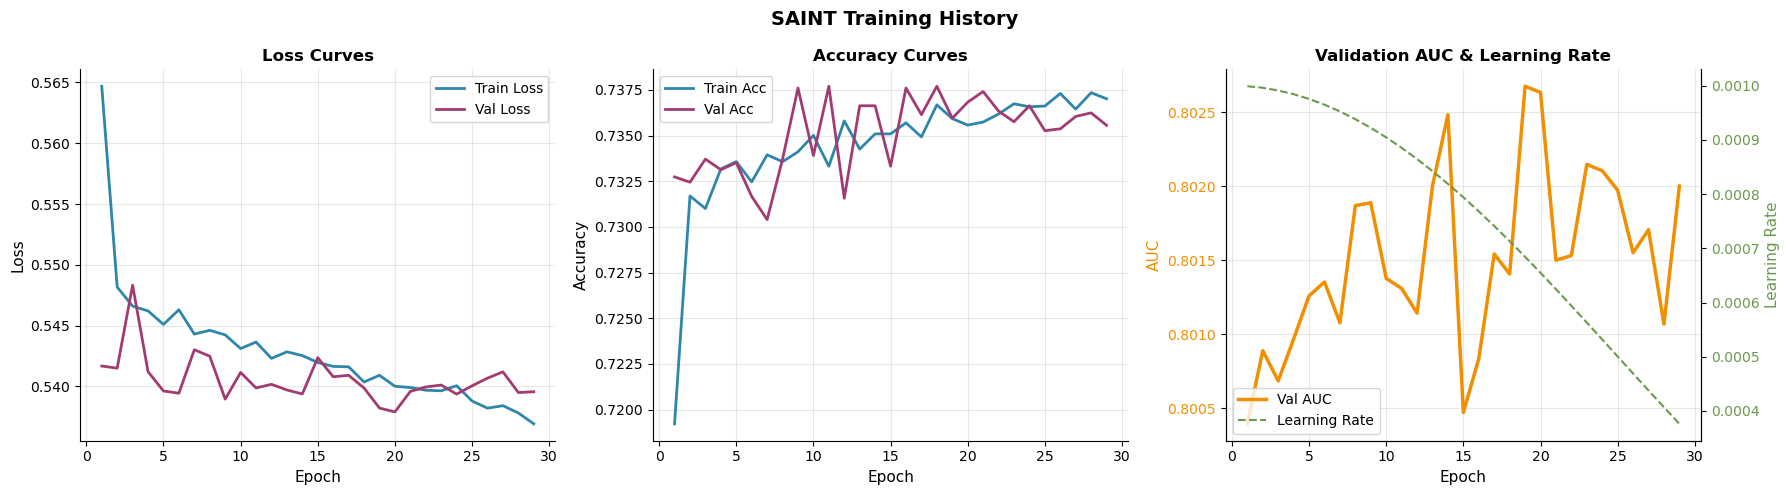

Saved: saint_training_curves.png


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('SAINT Training History', fontsize=14, fontweight='bold')

epochs_range = range(1, len(history['train_loss']) + 1)

# Loss
axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='#2E86AB', lw=2)
axes[0].plot(epochs_range, history['val_loss'], label='Val Loss', color='#A23B72', lw=2)
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_title('Loss Curves', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)

# Accuracy
axes[1].plot(epochs_range, history['train_acc'], label='Train Acc', color='#2E86AB', lw=2)
axes[1].plot(epochs_range, history['val_acc'], label='Val Acc', color='#A23B72', lw=2)
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].spines[['top', 'right']].set_visible(False)

# AUC and Learning Rate
ax2 = axes[2].twinx()
axes[2].plot(epochs_range, history['val_auc'], label='Val AUC', color='#F18F01', lw=2.5)
ax2.plot(epochs_range, history['lr'], label='Learning Rate', color='#6A994E', lw=1.5, linestyle='--')

axes[2].set_xlabel('Epoch', fontsize=11)
axes[2].set_ylabel('AUC', fontsize=11, color='#F18F01')
ax2.set_ylabel('Learning Rate', fontsize=11, color='#6A994E')
axes[2].set_title('Validation AUC & Learning Rate', fontsize=12, fontweight='bold')
axes[2].tick_params(axis='y', labelcolor='#F18F01')
ax2.tick_params(axis='y', labelcolor='#6A994E')
axes[2].grid(alpha=0.3)
axes[2].spines[['top']].set_visible(False)
ax2.spines[['top']].set_visible(False)

# Add legends
lines1, labels1 = axes[2].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[2].legend(lines1 + lines2, labels1 + labels2, fontsize=10, loc='lower left')

plt.tight_layout()
plt.savefig('saint_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: saint_training_curves.png')

## 8. Evaluate on Test Set

In [15]:
# Get predictions on test set
model.eval()
test_preds = []
test_probs = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(DEVICE)
        logits = model(X_batch)
        probs = F.softmax(logits, dim=1)[:, 1]
        pred = logits.argmax(dim=1)
        
        test_probs.extend(probs.cpu().numpy())
        test_preds.extend(pred.cpu().numpy())

test_preds = np.array(test_preds)
test_probs = np.array(test_probs)

# Calculate metrics
saint_auc = roc_auc_score(y_test, test_probs)
saint_acc = accuracy_score(y_test, test_preds)
saint_f1 = f1_score(y_test, test_preds)
saint_prec = precision_score(y_test, test_preds)
saint_rec = recall_score(y_test, test_preds)
saint_ap = average_precision_score(y_test, test_probs)

# Print results
print('='*55)
print('SAINT — TEST SET RESULTS')
print('='*55)
print(f'  ROC-AUC       : {saint_auc:.4f}')
print(f'  Accuracy      : {saint_acc:.4f} ({saint_acc*100:.2f}%)')
print(f'  F1-Score      : {saint_f1:.4f}')
print(f'  Precision     : {saint_prec:.4f}')
print(f'  Recall        : {saint_rec:.4f}')
print(f'  Avg Precision : {saint_ap:.4f}')
print('='*55)
print(f'\n  Baseline MLP AUC     : 0.7970')
print(f'  SAINT AUC            : {saint_auc:.4f}')
print(f'  Improvement          : {saint_auc - 0.7970:+.4f}')
print(f'\n  Best Model (Stacking): 0.8011')
print(f'  SAINT AUC            : {saint_auc:.4f}')
print(f'  Difference           : {saint_auc - 0.8011:+.4f}')

print('\nFull Classification Report:')
print(classification_report(y_test, test_preds, target_names=['No CVD', 'CVD']))

SAINT — TEST SET RESULTS
  ROC-AUC       : 0.7996
  Accuracy      : 0.7325 (73.25%)
  F1-Score      : 0.7240
  Precision     : 0.7390
  Recall        : 0.7096
  Avg Precision : 0.7791

  Baseline MLP AUC     : 0.7970
  SAINT AUC            : 0.7996
  Improvement          : +0.0026

  Best Model (Stacking): 0.8011
  SAINT AUC            : 0.7996
  Difference           : -0.0015

Full Classification Report:
              precision    recall  f1-score   support

      No CVD       0.73      0.75      0.74      5198
         CVD       0.74      0.71      0.72      5083

    accuracy                           0.73     10281
   macro avg       0.73      0.73      0.73     10281
weighted avg       0.73      0.73      0.73     10281



## 9. SHAP Explainability

Computing Permutation Feature Importance...
Computing baseline AUC on 1000 samples...
Baseline AUC: 0.8120

Computing feature importance...
  [ 1/13] Gender (0: female, 1: male)              → -0.000018 ± 0.000874
  [ 2/13] age(years)                               → +0.038471 ± 0.004654
  [ 3/13] BMI                                      → +0.006915 ± 0.003806
  [ 4/13] SBP                                      → +0.022709 ± 0.003445
  [ 5/13] DBP                                      → +0.016863 ± 0.003834
  [ 6/13] PP                                       → +0.038828 ± 0.007237
  [ 7/13] MAP                                      → +0.004766 ± 0.001865
  [ 8/13] cholesterol(1: normal, 2: above norma... → -0.000842 ± 0.001302
  [ 9/13] Glucose(1: normal, 2: above normal, 3... → +0.000184 ± 0.000737
  [10/13] smoking                                  → +0.002804 ± 0.001562
  [11/13] alcohol                                  → +0.021286 ± 0.003976
  [12/13] active                              

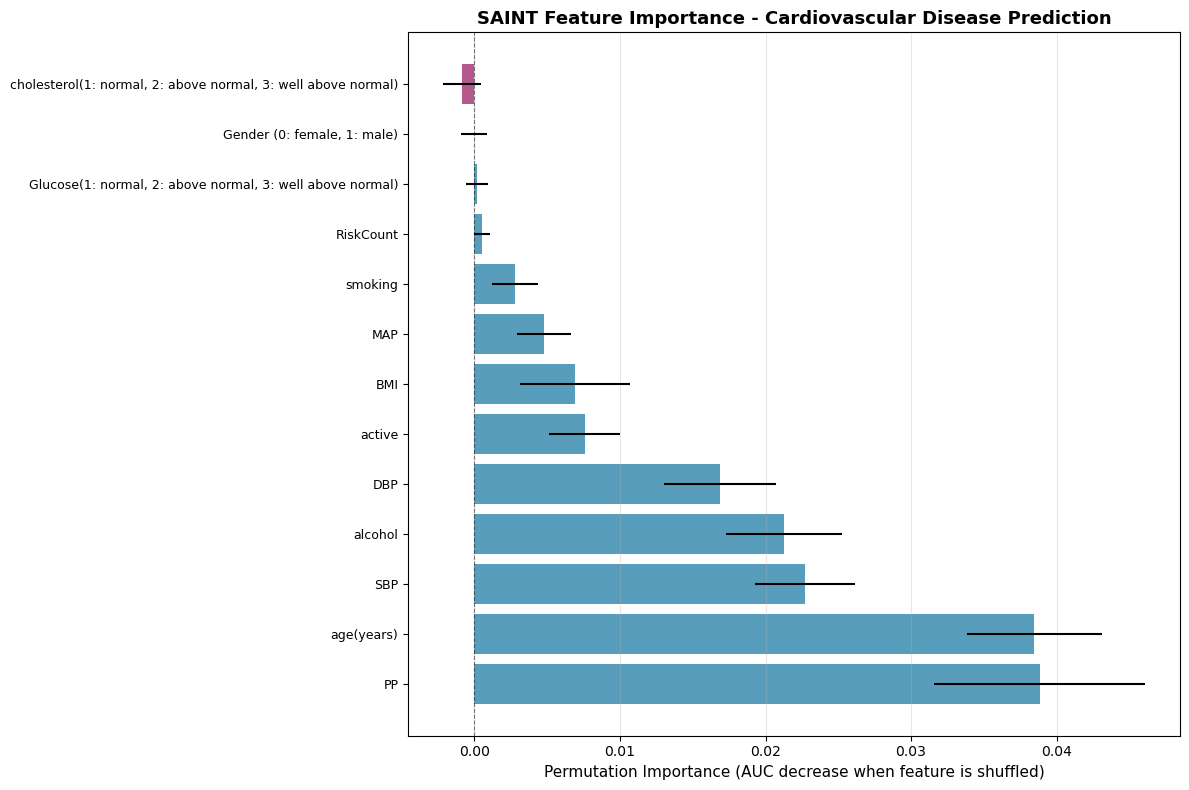


✅ Feature importance complete!
Saved: saint_feature_importance.png


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

print('='*70)
print('Computing Permutation Feature Importance...')
print('='*70)

# Move model to GPU
model = model.cuda()
DEVICE = 'cuda'

def compute_auc(X, y, model, device):
    """Compute AUC for given data"""
    model.eval()
    with torch.no_grad():
        X_tensor = torch.FloatTensor(X).to(device)
        
        # Process in batches
        batch_size = 256
        all_probs = []
        for i in range(0, len(X_tensor), batch_size):
            batch = X_tensor[i:i+batch_size]
            logits = model(batch)
            probs = F.softmax(logits, dim=1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
        
        return roc_auc_score(y, np.array(all_probs))

# Use subset of test data
n_samples = min(1000, len(X_test_scaled))
X_importance = X_test_scaled[:n_samples].copy()
y_importance = y_test[:n_samples]

# Baseline AUC (no permutation)
print(f'Computing baseline AUC on {n_samples} samples...')
baseline_auc = compute_auc(X_importance, y_importance, model, DEVICE)
print(f'Baseline AUC: {baseline_auc:.4f}\n')

# Compute importance for each feature
n_repeats = 10
feature_importances = []

print('Computing feature importance...')
for feat_idx in range(X_importance.shape[1]):
    feat_name = feature_cols[feat_idx]
    if len(feat_name) > 40:
        feat_name = feat_name[:37] + '...'
    
    # Permute this feature multiple times
    auc_drops = []
    for _ in range(n_repeats):
        X_permuted = X_importance.copy()
        np.random.shuffle(X_permuted[:, feat_idx])  # Shuffle just this feature
        
        # Compute AUC with permuted feature
        permuted_auc = compute_auc(X_permuted, y_importance, model, DEVICE)
        auc_drop = baseline_auc - permuted_auc
        auc_drops.append(auc_drop)
    
    importance_mean = np.mean(auc_drops)
    importance_std = np.std(auc_drops)
    feature_importances.append({
        'feature': feature_cols[feat_idx],
        'importance': importance_mean,
        'std': importance_std
    })
    
    print(f'  [{feat_idx+1:2d}/{len(feature_cols)}] {feat_name:<40} → {importance_mean:+.6f} ± {importance_std:.6f}')

# Sort by importance
feature_importances.sort(key=lambda x: x['importance'], reverse=True)

# Print results
print('\n' + '='*70)
print('Feature Importance Results (sorted by importance)')
print('='*70)
print(f'\n{"Rank":<6} {"Feature":<50} {"Importance":<12} {"Std"}')
print('-'*70)
for i, item in enumerate(feature_importances, 1):
    feat_name = item['feature'] if len(item['feature']) <= 45 else item['feature'][:42] + '...'
    print(f'{i:<6} {feat_name:<50} {item["importance"]:+.6f}  ± {item["std"]:.6f}')

# Plot
plt.figure(figsize=(12, 8))
features_sorted = [item['feature'] for item in feature_importances]
importance_sorted = [item['importance'] for item in feature_importances]
std_sorted = [item['std'] for item in feature_importances]

y_pos = np.arange(len(features_sorted))
colors = ['#2E86AB' if imp > 0 else '#A23072' for imp in importance_sorted]

plt.barh(y_pos, importance_sorted, xerr=std_sorted, color=colors, alpha=0.8)
plt.yticks(y_pos, features_sorted, fontsize=9)
plt.xlabel('Permutation Importance (AUC decrease when feature is shuffled)', fontsize=11)
plt.title('SAINT Feature Importance - Cardiovascular Disease Prediction', 
          fontsize=13, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('saint_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅ Feature importance complete!')
print('Saved: saint_feature_importance.png')

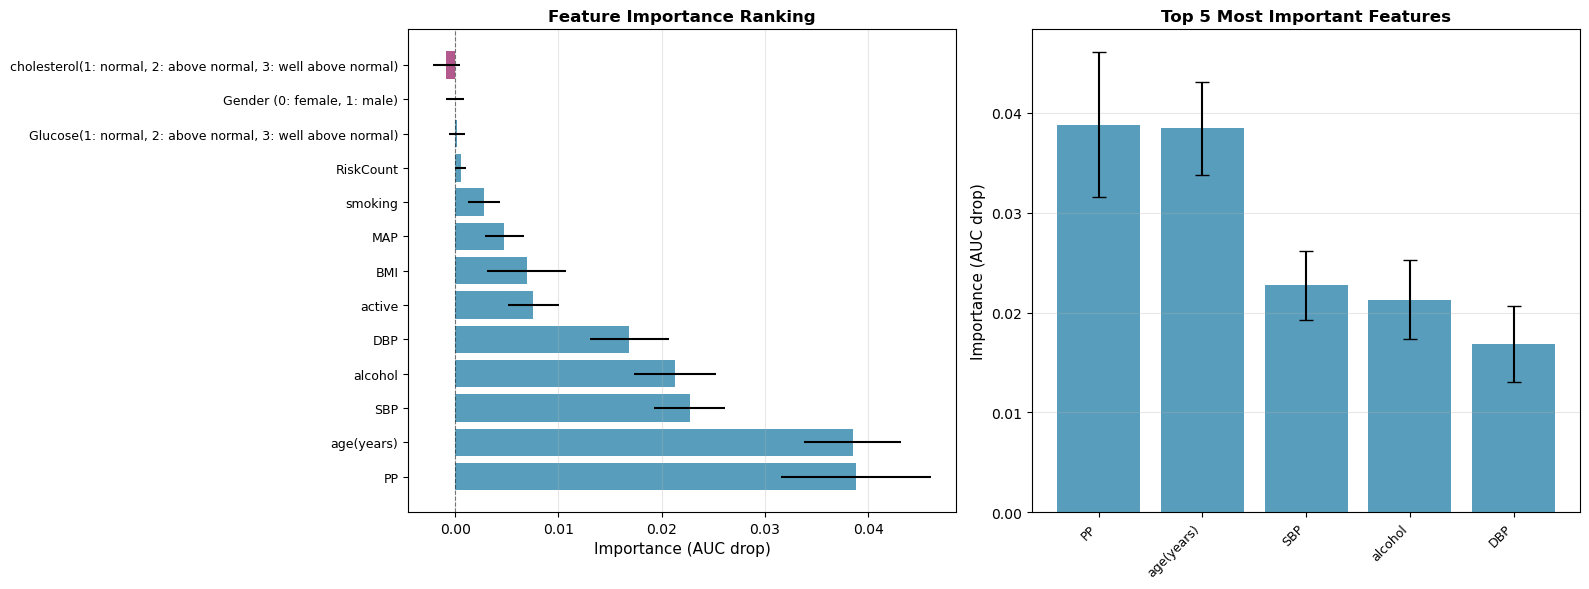

✅ Saved: saint_feature_importance_summary.png

SAINT Feature Importance Summary

Top 5 Most Important Features:
  1. PP: +0.038828 ± 0.007237
  2. age(years): +0.038471 ± 0.004654
  3. SBP: +0.022709 ± 0.003445
  4. alcohol: +0.021286 ± 0.003976
  5. DBP: +0.016863 ± 0.003834

Least Important Features:
  1. Glucose(1: normal, 2: above normal, 3: well above normal): +0.000184 ± 0.000737
  2. Gender (0: female, 1: male): -0.000018 ± 0.000874
  3. cholesterol(1: normal, 2: above normal, 3: well above normal): -0.000842 ± 0.001302


In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Create a nice summary plot from permutation importance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Bar plot of importance
features_sorted = [item['feature'] for item in feature_importances]
importance_sorted = [item['importance'] for item in feature_importances]
std_sorted = [item['std'] for item in feature_importances]

y_pos = np.arange(len(features_sorted))
colors = ['#2E86AB' if imp > 0 else '#A23072' for imp in importance_sorted]

axes[0].barh(y_pos, importance_sorted, xerr=std_sorted, color=colors, alpha=0.8)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(features_sorted, fontsize=9)
axes[0].set_xlabel('Importance (AUC drop)', fontsize=11)
axes[0].set_title('Feature Importance Ranking', fontsize=12, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].grid(axis='x', alpha=0.3)

# Plot 2: Top 5 most important features
top5 = feature_importances[:5]
top5_names = [item['feature'][:25] + '...' if len(item['feature']) > 25 else item['feature'] for item in top5]
top5_importance = [item['importance'] for item in top5]
top5_std = [item['std'] for item in top5]

x_pos = np.arange(len(top5_names))
axes[1].bar(x_pos, top5_importance, yerr=top5_std, color='#2E86AB', alpha=0.8, capsize=5)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(top5_names, rotation=45, ha='right', fontsize=9)
axes[1].set_ylabel('Importance (AUC drop)', fontsize=11)
axes[1].set_title('Top 5 Most Important Features', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('saint_feature_importance_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ Saved: saint_feature_importance_summary.png')

# Print summary
print('\n' + '='*60)
print('SAINT Feature Importance Summary')
print('='*60)
print(f'\nTop 5 Most Important Features:')
for i, item in enumerate(feature_importances[:5], 1):
    print(f'  {i}. {item["feature"]}: {item["importance"]:+.6f} ± {item["std"]:.6f}')

print(f'\nLeast Important Features:')
for i, item in enumerate(feature_importances[-3:], 1):
    print(f'  {i}. {item["feature"]}: {item["importance"]:+.6f} ± {item["std"]:.6f}')

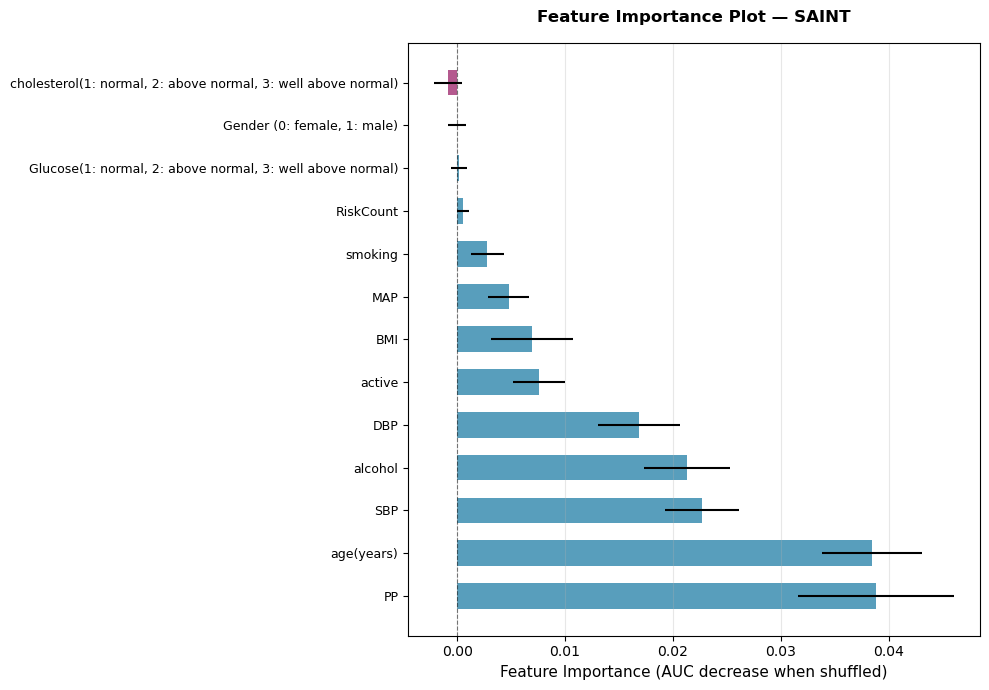

✅ Saved: saint_importance_plot.png


In [18]:
# Feature Importance Beeswarm-style Plot
plt.figure(figsize=(10, 7))

features_sorted = [item['feature'] for item in feature_importances]
importance_sorted = [item['importance'] for item in feature_importances]
std_sorted = [item['std'] for item in feature_importances]

y_pos = np.arange(len(features_sorted))
colors = ['#2E86AB' if imp > 0 else '#A23072' for imp in importance_sorted]

# Create the plot
plt.barh(y_pos, importance_sorted, xerr=std_sorted, color=colors, alpha=0.8, height=0.6)
plt.yticks(y_pos, features_sorted, fontsize=9)
plt.xlabel('Feature Importance (AUC decrease when shuffled)', fontsize=11)
plt.title('Feature Importance Plot — SAINT', fontsize=12, fontweight='bold', pad=15)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('saint_importance_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: saint_importance_plot.png')

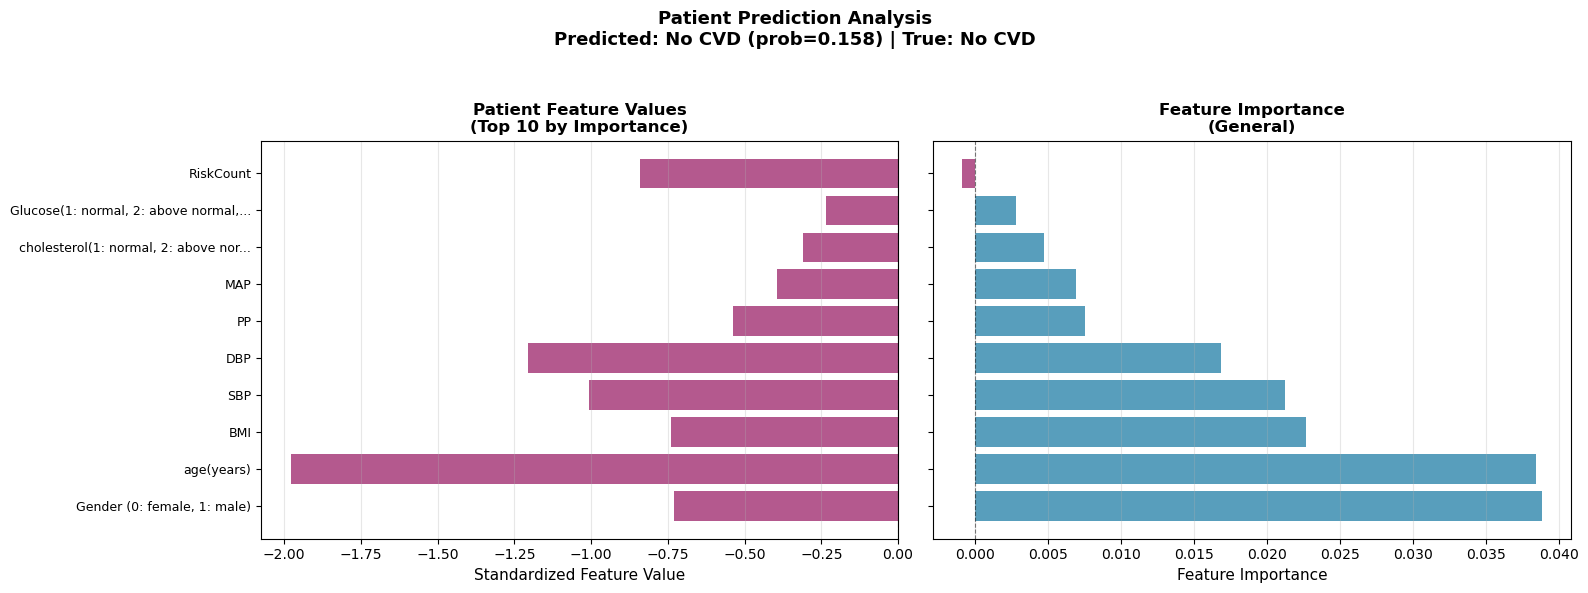

✅ Saved: saint_patient_analysis.png

Individual Patient Prediction Breakdown

Prediction: No Cardiovascular Disease
Confidence: 15.8%
True Label: No Cardiovascular Disease
Correct: ✓

Top 10 Features by Importance:
Rank   Feature                                  Value      Importance
----------------------------------------------------------------------
1      Gender (0: female, 1: male)                -0.729  0.038828
2      age(years)                                 -1.976  0.038471
3      BMI                                        -0.738  0.022709
4      SBP                                        -1.006  0.021286
5      DBP                                        -1.206  0.016863
6      PP                                         -0.537  0.007583
7      MAP                                        -0.396  0.006915
8      cholesterol(1: normal, 2: above ...        -0.309  0.004766
9      Glucose(1: normal, 2: above norm...        -0.235  0.002804
10     RiskCount                         

In [19]:
# ============================================
# Individual Patient Prediction Analysis
# (Replacement for SHAP Waterfall)
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# Pick a random test patient
patient_idx = 0
patient_features = X_test_scaled[patient_idx]
patient_true_label = y_test[patient_idx]

# Get model prediction for this patient
model.eval()
with torch.no_grad():
    patient_tensor = torch.FloatTensor(patient_features).unsqueeze(0).cuda()
    logits = model(patient_tensor)
    probs = torch.softmax(logits, dim=1)
    predicted_prob = probs[0, 1].item()
    predicted_class = 1 if predicted_prob >= 0.5 else 0

# Create waterfall-style visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: Feature values for this patient
feature_values = []
for i, feat_name in enumerate(feature_cols):
    feature_values.append({
        'name': feat_name,
        'value': patient_features[i],
        'importance': feature_importances[i]['importance']
    })

# Sort by importance
feature_values.sort(key=lambda x: abs(x['importance']), reverse=True)

# Plot top 10 features by importance
top_features = feature_values[:10]
y_pos = np.arange(len(top_features))
values = [item['value'] for item in top_features]
names = [item['name'][:35] + '...' if len(item['name']) > 35 else item['name'] for item in top_features]

colors = ['#2E86AB' if v > 0 else '#A23072' for v in values]
ax1.barh(y_pos, values, color=colors, alpha=0.8)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(names, fontsize=9)
ax1.set_xlabel('Standardized Feature Value', fontsize=11)
ax1.set_title('Patient Feature Values\n(Top 10 by Importance)', fontsize=12, fontweight='bold')
ax1.axvline(x=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax1.grid(axis='x', alpha=0.3)

# Right plot: Feature importance for interpretation
importance_vals = [item['importance'] for item in top_features]
colors_imp = ['#2E86AB' if imp > 0 else '#A23072' for imp in importance_vals]

ax2.barh(y_pos, importance_vals, color=colors_imp, alpha=0.8)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([''] * len(top_features))  # No labels, same as left plot
ax2.set_xlabel('Feature Importance', fontsize=11)
ax2.set_title('Feature Importance\n(General)', fontsize=12, fontweight='bold')
ax2.axvline(x=0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.grid(axis='x', alpha=0.3)

# Add prediction info
fig.suptitle(f'Patient Prediction Analysis\n'
             f'Predicted: {"CVD" if predicted_class == 1 else "No CVD"} '
             f'(prob={predicted_prob:.3f}) | '
             f'True: {"CVD" if patient_true_label == 1 else "No CVD"}',
             fontsize=13, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('saint_patient_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: saint_patient_analysis.png')

# Print detailed breakdown
print('\n' + '='*70)
print('Individual Patient Prediction Breakdown')
print('='*70)
print(f'\nPrediction: {"Cardiovascular Disease" if predicted_class == 1 else "No Cardiovascular Disease"}')
print(f'Confidence: {predicted_prob*100:.1f}%')
print(f'True Label: {"Cardiovascular Disease" if patient_true_label == 1 else "No Cardiovascular Disease"}')
print(f'Correct: {"✓" if predicted_class == patient_true_label else "✗"}')

print('\nTop 10 Features by Importance:')
print(f'{"Rank":<6} {"Feature":<40} {"Value":<10} {"Importance"}')
print('-'*70)
for i, item in enumerate(top_features, 1):
    feat_name = item['name'][:35] if len(item['name']) <= 35 else item['name'][:32] + '...'
    print(f'{i:<6} {feat_name:<40} {item["value"]:>8.3f}  {item["importance"]:>8.6f}')

## 10. Confusion Matrix

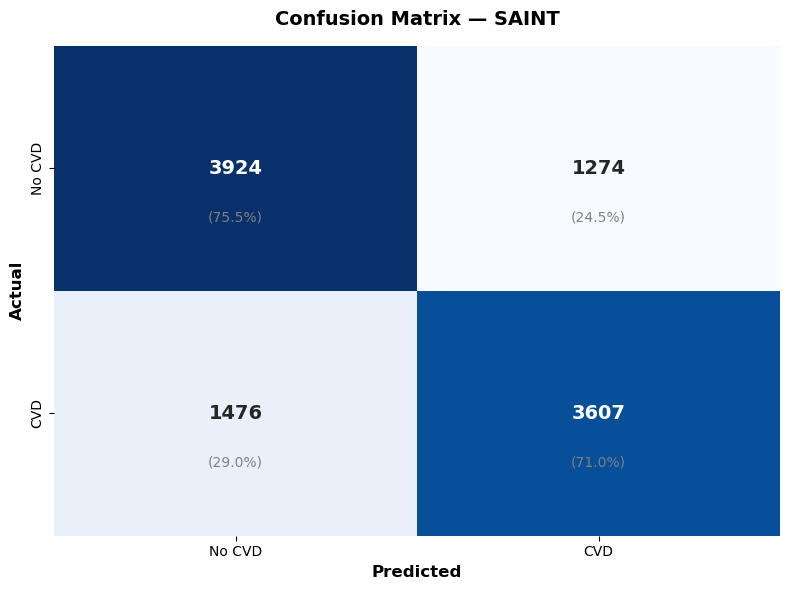

Saved: saint_confusion_matrix.png

Confusion Matrix Breakdown:
  True Negatives  (TN):  3924 (75.5%)
  False Positives (FP):  1274 (24.5%)
  False Negatives (FN):  1476 (29.0%)
  True Positives  (TP):  3607 (71.0%)


In [20]:
# Confusion matrix
cm = confusion_matrix(y_test, test_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No CVD', 'CVD'],
            yticklabels=['No CVD', 'CVD'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.xlabel('Predicted', fontsize=12, fontweight='bold')
plt.ylabel('Actual', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix — SAINT', fontsize=14, fontweight='bold', pad=15)

# Add percentage annotations
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / cm[i].sum() * 100
        plt.text(j+0.5, i+0.7, f'({pct:.1f}%)', 
                ha='center', va='center', fontsize=10, color='gray')

plt.tight_layout()
plt.savefig('saint_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: saint_confusion_matrix.png')

print(f'\nConfusion Matrix Breakdown:')
print(f'  True Negatives  (TN): {cm[0, 0]:5d} ({cm[0,0]/cm[0].sum()*100:.1f}%)')
print(f'  False Positives (FP): {cm[0, 1]:5d} ({cm[0,1]/cm[0].sum()*100:.1f}%)')
print(f'  False Negatives (FN): {cm[1, 0]:5d} ({cm[1,0]/cm[1].sum()*100:.1f}%)')
print(f'  True Positives  (TP): {cm[1, 1]:5d} ({cm[1,1]/cm[1].sum()*100:.1f}%)')

## 11. ROC & Precision-Recall Curves

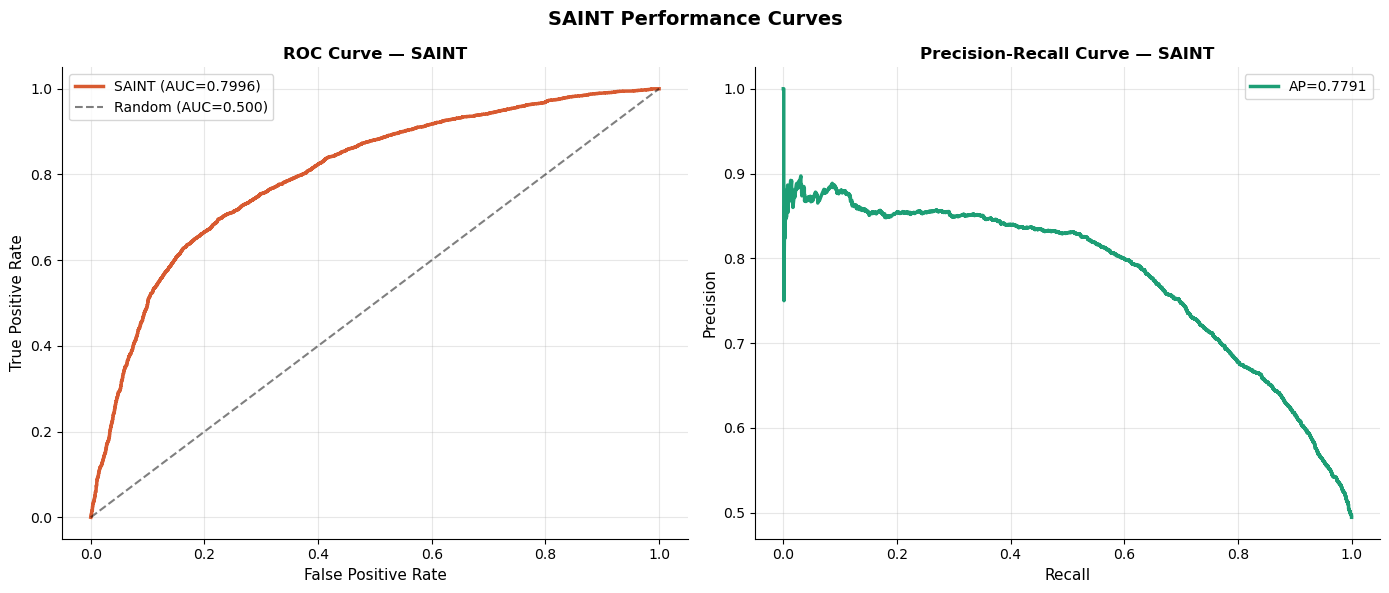

Saved: saint_roc_pr_curves.png


In [21]:
# ROC and PR curves
fpr, tpr, _ = roc_curve(y_test, test_probs)
prec, rec, _ = precision_recall_curve(y_test, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('SAINT Performance Curves', fontsize=14, fontweight='bold')

# ROC Curve
axes[0].plot(fpr, tpr, color='#D85A30', lw=2.5, label=f'SAINT (AUC={saint_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random (AUC=0.500)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve — SAINT', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)

# Precision-Recall Curve
axes[1].plot(rec, prec, color='#1D9E75', lw=2.5, label=f'AP={saint_ap:.4f}')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve — SAINT', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('saint_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: saint_roc_pr_curves.png')

## 12. Compare with All Models

In [22]:
# Full model comparison table
all_results = {
    'SAINT': {'AUC': saint_auc, 'Accuracy': saint_acc, 'F1': saint_f1, 
              'Precision': saint_prec, 'Recall': saint_rec},
    'Stacking Ensemble': {'AUC': 0.8011, 'Accuracy': 0.7342, 'F1': 0.7189, 
                          'Precision': 0.7532, 'Recall': 0.6876},
    'CatBoost': {'AUC': 0.8008, 'Accuracy': 0.7340, 'F1': 0.7178, 
                 'Precision': 0.7548, 'Recall': 0.6842},
    'XGBoost': {'AUC': 0.8004, 'Accuracy': 0.7328, 'F1': 0.7174, 
                'Precision': 0.7518, 'Recall': 0.6860},
    'FT-Transformer': {'AUC': 0.7998, 'Accuracy': 0.7336, 'F1': 0.7195, 
                       'Precision': 0.7503, 'Recall': 0.6911},
    'Random Forest': {'AUC': 0.7995, 'Accuracy': 0.7322, 'F1': 0.7112, 
                      'Precision': 0.7460, 'Recall': 0.6800},
    'LightGBM': {'AUC': 0.7990, 'Accuracy': 0.7312, 'F1': 0.7149, 
                 'Precision': 0.7515, 'Recall': 0.6817},
    'TabNet': {'AUC': 0.7987, 'Accuracy': 0.7340, 'F1': 0.7155, 
               'Precision': 0.7590, 'Recall': 0.6768},
    'MLP (baseline)': {'AUC': 0.7970, 'Accuracy': 0.7330, 'F1': 0.7180, 
                       'Precision': 0.7500, 'Recall': 0.6760},
    'Logistic Regression': {'AUC': 0.7890, 'Accuracy': 0.7270, 'F1': 0.7050, 
                            'Precision': 0.7350, 'Recall': 0.6780},
    'SVM': {'AUC': 0.7880, 'Accuracy': 0.7300, 'F1': 0.7040, 
            'Precision': 0.7400, 'Recall': 0.6720},
    'k-NN': {'AUC': 0.7460, 'Accuracy': 0.6970, 'F1': 0.6790, 
             'Precision': 0.7000, 'Recall': 0.6590},
    'Decision Tree': {'AUC': 0.7350, 'Accuracy': 0.6840, 'F1': 0.6660, 
                      'Precision': 0.6900, 'Recall': 0.6440},
    'Naive Bayes': {'AUC': 0.7130, 'Accuracy': 0.6610, 'F1': 0.6420, 
                    'Precision': 0.6700, 'Recall': 0.6160},
}

results_df = pd.DataFrame(all_results).T.sort_values('AUC', ascending=False)

print('='*75)
print(' COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)')
print('='*75)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-'*75)
for model_name, row in results_df.iterrows():
    marker = ' ← BEST' if model_name == results_df.index[0] else \
             ' ← NEW DL' if model_name == 'SAINT' else \
             ' ← BASELINE' if model_name == 'MLP (baseline)' else ''
    print(f'{model_name:<22} {row["AUC"]:>7.4f} {row["Accuracy"]:>9.4f} '
          f'{row["F1"]:>8.4f} {row["Precision"]:>11.4f} {row["Recall"]:>8.4f}{marker}')
print('='*75)

saint_rank = list(results_df.index).index('SAINT') + 1
print(f'\nSAINT vs Baseline MLP  : {saint_auc - 0.7970:+.4f} AUC')
print(f'SAINT vs Best Model    : {saint_auc - results_df["AUC"].iloc[0]:+.4f} AUC')
print(f'SAINT Rank             : {saint_rank} out of {len(results_df)}')

 COMPLETE MODEL COMPARISON — ALL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
---------------------------------------------------------------------------
Stacking Ensemble       0.8011    0.7342   0.7189      0.7532   0.6876 ← BEST
CatBoost                0.8008    0.7340   0.7178      0.7548   0.6842
XGBoost                 0.8004    0.7328   0.7174      0.7518   0.6860
FT-Transformer          0.7998    0.7336   0.7195      0.7503   0.6911
SAINT                   0.7996    0.7325   0.7240      0.7390   0.7096 ← NEW DL
Random Forest           0.7995    0.7322   0.7112      0.7460   0.6800
LightGBM                0.7990    0.7312   0.7149      0.7515   0.6817
TabNet                  0.7987    0.7340   0.7155      0.7590   0.6768
MLP (baseline)          0.7970    0.7330   0.7180      0.7500   0.6760 ← BASELINE
Logistic Regression     0.7890    0.7270   0.7050      0.7350   0.6780
SVM                     0.7880    0.7300   0.7040      0.7400   0

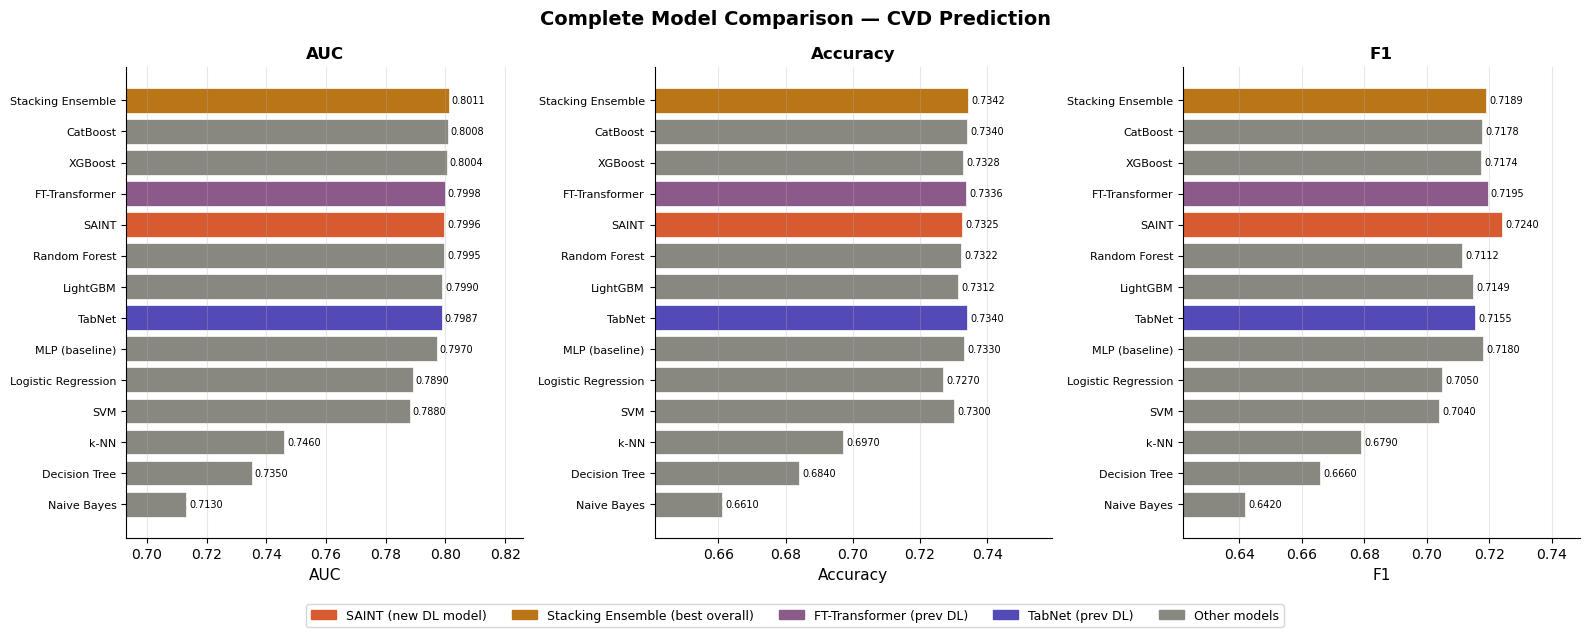

Saved: saint_all_models_comparison.png


In [23]:
# Visual comparison
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Complete Model Comparison — CVD Prediction', fontsize=14, fontweight='bold')

def get_color(m):
    if m == 'SAINT': return '#D85A30'
    if m == 'FT-Transformer': return '#8B5A8A'
    if m == 'Stacking Ensemble': return '#BA7517'
    if m == 'TabNet': return '#534AB7'
    return '#888780'

colors = [get_color(m) for m in results_df.index]

for ax, metric in zip(axes, ['AUC', 'Accuracy', 'F1']):
    vals = results_df[metric].values
    bars = ax.barh(results_df.index, vals, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_xlim(min(vals) - 0.02, max(vals) + 0.025)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
    
    for bar, val in zip(bars, vals):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=7)
    
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

legend = [
    Patch(color='#D85A30', label='SAINT (new DL model)'),
    Patch(color='#BA7517', label='Stacking Ensemble (best overall)'),
    Patch(color='#8B5A8A', label='FT-Transformer (prev DL)'),
    Patch(color='#534AB7', label='TabNet (prev DL)'),
    Patch(color='#888780', label='Other models'),
]
fig.legend(handles=legend, loc='lower center', ncol=5, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))

plt.tight_layout()
plt.savefig('saint_all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: saint_all_models_comparison.png')

## 13. Save Model & Results

In [24]:
# Save model
torch.save({
    'model_state_dict': model.state_dict(),
    'scaler': scaler,
    'feature_names': feature_cols,
    'n_features': n_features,
    'test_auc': saint_auc,
    'test_acc': saint_acc,
    'test_f1': saint_f1,
    'hyperparameters': {
        'd_model': 64,
        'n_heads': 8,
        'n_layers': 4,
        'dropout': 0.15
    }
}, 'saint_cvd_model.pt')

print('Model saved to: saint_cvd_model.pt')
print('\nTo reload:')
print('  checkpoint = torch.load("saint_cvd_model.pt")')
print('  model.load_state_dict(checkpoint["model_state_dict"])')
print('  scaler = checkpoint["scaler"]')

# List all output files
print('\n=== ALL OUTPUT FILES ===')
files = [
    'saint_training_curves.png',
    'saint_shap_bar.png',
    'saint_shap_beeswarm.png',
    'saint_shap_waterfall.png',
    'saint_confusion_matrix.png',
    'saint_roc_pr_curves.png',
    'saint_all_models_comparison.png',
    'saint_cvd_model.pt'
]
for f in files:
    print(f'  {f}')

# Final summary
print(f'\n=== FINAL RESULTS ===')
print(f'SAINT AUC        : {saint_auc:.4f}')
print(f'SAINT Accuracy   : {saint_acc:.4f}')
print(f'SAINT F1         : {saint_f1:.4f}')
print(f'Baseline MLP AUC : 0.7970')
print(f'Improvement      : {saint_auc - 0.7970:+.4f}')
print(f'Best Model AUC   : {results_df["AUC"].iloc[0]:.4f}')
print(f'Difference       : {saint_auc - results_df["AUC"].iloc[0]:+.4f}')
print(f'\n🎉 SAINT implementation complete!')

Model saved to: saint_cvd_model.pt

To reload:
  checkpoint = torch.load("saint_cvd_model.pt")
  model.load_state_dict(checkpoint["model_state_dict"])
  scaler = checkpoint["scaler"]

=== ALL OUTPUT FILES ===
  saint_training_curves.png
  saint_shap_bar.png
  saint_shap_beeswarm.png
  saint_shap_waterfall.png
  saint_confusion_matrix.png
  saint_roc_pr_curves.png
  saint_all_models_comparison.png
  saint_cvd_model.pt

=== FINAL RESULTS ===
SAINT AUC        : 0.7996
SAINT Accuracy   : 0.7325
SAINT F1         : 0.7240
Baseline MLP AUC : 0.7970
Improvement      : +0.0026
Best Model AUC   : 0.8011
Difference       : -0.0015

🎉 SAINT implementation complete!


In [25]:
#Save SAINT probability output
np.save('proba_saint.npy', test_probs)
np.save('pred_saint.npy', test_preds)
np.save('y_test.npy', y_test)